<a href="https://colab.research.google.com/github/ByNeex/ByNeex/blob/main/TP1_KMAXPP02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# KMAXPP02 - Probabilités & statistiques continues  - TP1
#### Université de Toulouse, Printemps 2025-2026, L3 Maths-TP

### Consignes pour le Compte-rendu de séance :
- **Support :** Complétez ce fichier `TP1_KMAXPP02.ipynb` avec vos codes et commentaires.
- **Rendu :** Le dépôt est **strictement individuel**. Veuillez soumettre votre notebook via le lien PigeonFiles qui sera communiqué.
- **Délai :** La date limite de soumission est fixée au **Mardi 23h59** (soit quatre jours après la séance).
- **Format du Fichier :** Veuillez nommer votre fichier impérativement `NOM-PRENOM-TP1_KMAXPP02.ipynb`.
- **Évaluation :** Votre note repose non seulement sur le code fonctionnel, mais aussi sur les **commentaires mathématiques et informatiques fournis** pour expliquer votre démarche et vos résultats.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from numpy import linspace, sqrt, pi, exp, log, cos, sin
from numpy.random import default_rng
from scipy.special import erfinv # Utilisé pour la question Bonus
from scipy.stats import poisson, binom, cauchy # Utile pour les calculs de densités théoriques

# Initialisation de la graine aléatoire pour la reproductibilité
rng = default_rng(42)

## Partie I. Prise en Main & Générateurs Intégrés

### Brique de base : Simulation d'une variable aléatoire uniforme $\mathcal{U}([0,1])$

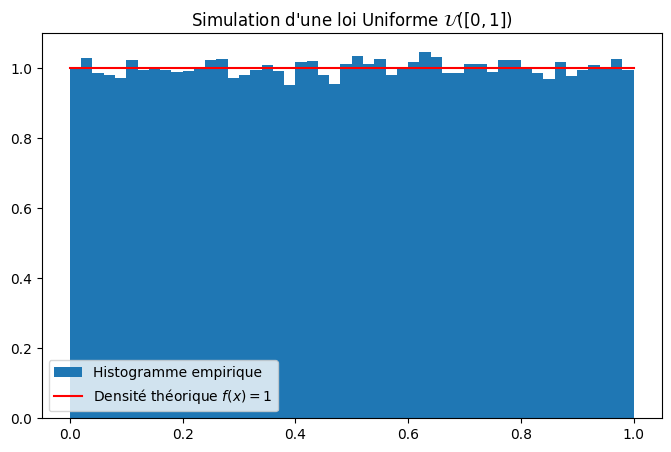

In [2]:
N = 10**5
X = rng.random(N)  # Génère N réalisations de U([0,1])

plt.figure(figsize=(8, 5))
plt.hist(X, bins=np.linspace(0, 1, 51), density=True, label='Histogramme empirique')
# density=True normalise l'histogramme pour que l'aire totale soit égale à 1.

plt.plot([0, 1], [1, 1], 'r', label='Densité théorique $f(x)=1$')
plt.title("Simulation d'une loi Uniforme $\\mathcal{U}([0,1])$")
plt.legend()
plt.show()

### Exercice 1. Utilisation des générateurs aléatoires intégrés
Utiliser les fonctions `rng.toto` (où `toto` est la loi désirée) pour simuler $N=10^5$ réalisations pour les lois continues suivantes. Pour chaque loi :
1. Simuler $N$ réalisations.
2. Tracer l'histogramme normalisé (`density=True`).
3. Superposer la **densité théorique** $f_X(x)$ de la loi correspondante (en ligne rouge) sur l'intervalle pertinent.

**Rappel :** Les lois sont : $\text{Exp}(\lambda)$, $\mathcal{N}(\mu, \sigma^2)$, $\text{Cauchy}(x_0, \gamma)$.

#### Méthode de Simulation avec les Générateurs Intégrés de NumPy

Pour réaliser l'Exercice 1, vous utiliserez les fonctions spécifiques du module `numpy.random` (ici abrégé `rng`).

1.  **Documentation :** Commencez par consulter la documentation officielle de NumPy pour la loi désirée (ex: [Loi Exponentielle](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.exponential.html) ou [Loi Normale](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html)).
2.  **Paramétrage (`loc` et `scale`) :**
    La plupart des fonctions de génération de NumPy simulent par défaut la loi *standard* correspondante. Pour obtenir une variable aléatoire $X'$ d'une loi générale, elles utilisent la relation suivante, appliquée à une version standard $X$ de la même loi :
    $$X' = \text{scale} \cdot X + \text{loc}$$
    *   Le paramètre `loc` représente le **paramètre de localisation**.
    *   Le paramètre `scale` représente le **paramètre d'échelle**.
    *   **Exemple pour la Loi Normale $\mathcal{N}(\mu, \sigma^2)$ :** La version standard est $\mathcal{N}(0, 1)$. Pour obtenir $\mathcal{N}(\mu, \sigma^2)$, vous devez choisir : `loc = mu` et `scale = sigma` ($\sigma = \sqrt{\sigma^2}$).

3.  **Taille de l'échantillon :** La taille $N$ du tableau de réalisations doit être passée via le paramètre nommé `size=N` (ou `size=(k, l)` pour un tableau multidimensionnel, mais `size=N` dans ce TP).

Appliquez cette méthode pour choisir correctement les paramètres des lois de l'Exercice 1.

a. Loi **Exponentielle** de paramètre $\lambda=4$. ($f_X(x)=4e^{-4x}$ pour $x\ge 0$)

b. Loi **Normale** de moyenne $\mu=2$ et de variance $\sigma^2=4$ (donc $\sigma=2$).

c. Loi de **Cauchy standard** ($x_0=0, \gamma=1$).

## Partie II. La Méthode de la Fonction de Quantile (Transformation Inverse)

### Rappel Théorique
Soit $U$ une variable aléatoire de loi uniforme sur $[0,1]$. Si $X$ est une variable aléatoire à densité $f_X$, on a montré qu'en inversant sa fonction de répartition $F_X$ on obtient la fonction de quantile $F_X^{-1}$ telle que $X\stackrel{\mathcal{L}}{=}F_X^{-1}(U)$.


### Exercice 2. Application de la méthode de Quantile
Reprendre les questions de l'exercice 1 pour les lois Exponentielle et Cauchy, mais cette fois **sans utiliser les générateurs intégrés** de Python (seulement `rng.random`), en implémentant l'algorithme universel $X=F_X^{-1}(U)$.

a. Loi **Exponentielle** de paramètre $\lambda=4$.

b. Loi de **Cauchy standard**.

Pour chaque loi, valider le résultat en superposant l'histogramme de vos simulations à la densité théorique.

In [ ]:
# a. Loi Exponentielle (lambda=4)


In [ ]:
# b. Loi de Cauchy standard


## Partie III. Méthode du Rejet

### Exercice 3. Implémentation de la Méthode du Rejet
Soit $X$ une variable aléatoire de densité $f$, et $Y$ une variable aléatoire de densité $g$, telle qu'il existe une constante $C < \infty$ vérifiant $f(x) \le C g(x)$ pour tout $x$.
L'algorithme du rejet permet de simuler $X$ à partir de $Y$ :

**Algorithme :**
1. Simuler $Y \sim g$.
2. Simuler $U \sim \mathcal{U}([0,1])$, indépendamment de $Y$.
3. Si $U \le \frac{f(Y)}{C g(Y)}$, **accepter** $Y$ comme une réalisation de $X$. Sinon, **rejeter** $Y$ et recommencer à l'étape 1.

**Objectif :** Simuler des réalisations de la loi **Normale Standard tronquée à $[-3, 3]$** (densité $f$) à partir d'une loi **Uniforme $\mathcal{U}([-3, 3])$** (densité $g$).

1. **Déterminer $f(x)$ et $g(x)$** sur l'intervalle $[-3, 3]$ et $\mathbf{C}$.
    - $f(x) = \frac{1}{\sqrt{2\pi}} e^{-x^2/2}$ (normalisée sur $\mathbb{R}$), mais doit être normalisée sur $[-3, 3]$. *Astuce : Pour l'algorithme de rejet, il suffit que $f(x)$ soit proportionnelle à la densité souhaitée sur $[-3,3]$*. On prendra $f_{non-norm.}(x) = e^{-x^2/2}$ (pour $x\in[-3,3]$).
    - $g(x) = \frac{1}{6}$ sur $[-3, 3]$ (densité de $\mathcal{U}([-3, 3])$).
    - Calculer $C = \max_{x \in [-3, 3]} \frac{f_{non-norm.}(x)}{g(x)}$.
2. **Écrire une fonction** qui génère **une** seule réalisation de $X$ en utilisant l'algorithme du rejet.
3. **Générer $N=10^4$ réalisations** de $X$ en appelant cette fonction.
4. **Valider** : Tracer l'histogramme des réalisations obtenues et superposer la densité théorique $f_{non-norm.}(x)$ (ou $f_{norm.}(x)$ pour l'aspect de la courbe) sur $[-3, 3]$.
5. **Commenter le taux d'acceptation** : Quel est le nombre moyen d'essais avant d'accepter une réalisation ? (Théoriquement, c'est $C$).

## Bonus : Optionnel à faire

### Exercice B1. Loi Normale Standard via Transformation Inverse
    
La fonction de répartition $F_{\mathcal{N}(0,1)}(x) = \frac{1}{2} \left(1 + \mathrm{erf}\left(\frac{x}{\sqrt{2}}\right)\right)$ ne peut pas être inversée explicitement. Pour l'inverser, on utilise la fonction `scipy.special.erfinv` qui est l'inverse de la fonction d'erreur $\mathrm{erf}(x) = \frac{2}{\sqrt{\pi}} \int_0^x e^{-t^2} dt$.

1. Montrer que l'inverse de $F_{\mathcal{N}(0,1)}(u)$ est donnée par :
$$F_{\mathcal{N}(0,1)}^{-1}(u) = \sqrt{2} \cdot \mathrm{erfinv}(2u-1)$$
2. Implémenter et valider cette formule en simulant $N=10^5$ réalisations de $\mathcal{N}(0,1)$ et en superposant l'histogramme à la densité théorique.

### Exercice B2. Tir à l'arc (Simulation d'un couple $(T, D)$)
Un archer attend un temps aléatoire $T$ avant de tirer une flèche à une distance aléatoire $D$. Représenter 1000 réalisations du point $(T,D)$ dans le plan $(x,y)$ (avec `plt.plot(T, D, '.')`) pour les cas suivants :

**Rappel :** Pour simuler une v.a. conditionnelle $D | T=t$, on utilise la loi de $D$ paramétrée par $t$ (ex: $D|T=t \sim \mathcal{U}([0, 2t])$). On simule d'abord $T$, puis on simule $D$ en utilisant la valeur obtenue pour $T$.

1. **Cas Indépendant :** $T$ suit une loi exponentielle de paramètre $1/3$ et $D$ est indépendante de $T$, de loi uniforme sur $[0,6]$.
2. **Cas Dépendant (1) :** $T$ suit une loi exponentielle de paramètre $1/3$ et, sachant $T$, $D$ suit une loi uniforme sur $[0,2T]$.
3. **Cas Dépendant (2) :** $T$ suit une loi exponentielle de paramètre $1/3$ et, sachant $T$, $D$ suit une loi uniforme sur $[0,1/(T+1)]$.
4. **Commenter** les formes obtenues et expliquer pourquoi elles sont cohérentes avec les hypothèses d'indépendance/dépendance.